# Exp 1 : Figure 1 B C D

In [1]:
import pandas as pd 
import numpy as np
import os as os
import matplotlib.pyplot as plt
import seaborn as sns
import csv
from tqdm import tqdm
tqdm.pandas()
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import json
from scipy.stats import binomtest
import statsmodels.stats.multitest as stm

In [2]:
# load the data
# access the conditions data
all_conditions = pd.read_csv('../Combined_data/'+'preliminary_set_up.csv')

| Index | Route                  | Length      | Error |
|-------|------------------------|------------|-------|
| 0     | [2, 5, 4, 3, 6, 7, 8, 9] | 347.751230 | 0.00  |
| 1     | [2, 4, 5, 3, 6, 7, 8, 9] | 348.167782 | 0.12  |
| 2     | [2, 3, 4, 5, 6, 7, 8, 9] | 348.980395 | 0.35  |
| 3     | [2, 4, 5, 6, 3, 7, 8, 9] | 354.301642 | 1.88  |


In [3]:
def Euclidean_Dist(df1, df2, cols=['x','y']):
    
    return np.linalg.norm(df1[cols].values - df2[cols].values,
                   axis=1)

# Load Exp1 data : 

In [4]:
# load the data set for sequence of experiment 1 data :


DATA = pd.read_csv('../Combined_data/'+'PRE_DATA.csv',index_col = 0 )
DATA_nodemo = DATA.loc[DATA.Session != 'demo_session'] 
DATA_nodemo['trial'] = pd.to_numeric(DATA_nodemo['trial'], errors='coerce')

C:\Users\chado\AppData\Local\Temp\ipykernel_3940\1339295551.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DATA_nodemo['trial'] = pd.to_numeric(DATA_nodemo['trial'], errors='coerce')


In [5]:
# number of diffrent sequences independantly of durection of execution per scale : 
for_comp = DATA_nodemo
results = []

for (scale, cond), df in for_comp.groupby(['Scale', 'Configuration']):
    count_df = df.visits.value_counts().to_frame().reset_index()
    count_df.columns = ['visits', 'count']
    
    count_df['visits'] = count_df['visits'].apply(lambda x: x.split('-')[1:-1])
    
    processed = set()
    final_counts = []

    for i, row in count_df.iterrows():
        
        seq_tuple = tuple(row.visits)
        rev_seq_tuple = tuple(reversed(row.visits))

        if seq_tuple in processed or rev_seq_tuple in processed:
            continue

        reversed_count = count_df.loc[count_df['visits'].apply(lambda x: tuple(x) == rev_seq_tuple), 'count'].sum()
        original_count = row['count']
        total_count = original_count + reversed_count
        if seq_tuple[-1] == '10':
            final_counts.append({'scale': scale, 'cond': cond, 'sequence': seq_tuple, 'count': total_count})
        else : 
            final_counts.append({'scale': scale, 'cond': cond, 'sequence': rev_seq_tuple, 'count': total_count})
        

        processed.add(seq_tuple)
        processed.add(rev_seq_tuple)

    results.extend(final_counts)

# Convert results to DataFrame
final_df = pd.DataFrame(results)

In [6]:
# folder to ave the figures : 
fig_folder = '../Figure_paper/'

In [7]:
def get_percentages(grp):
    total = grp.sum()    
    percentage = grp / total * 100  # Actual percentage calculation
    return pd.DataFrame({'percentage': percentage})

## Fig 1B C1

C:\Users\chado\AppData\Local\Temp\ipykernel_3940\3284408474.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['sequence'].loc[df.percentage< 10 ] = 'others'
C:\Users\chado\AppData\Local\Temp\ipykernel_3940\3284408474.py:5: SettingWithCo

Original Legend Labels: ['R1', 'R2', 'R3', 'others']


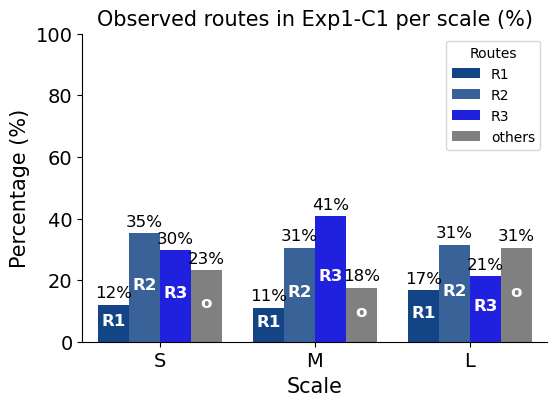

In [8]:
df = final_df.loc[final_df.cond == 'C2']
df = df.rename(columns={"count": "total"})

df.loc[:,['percentage']] = df.groupby('scale')['total'].apply(get_percentages).reset_index(level=0, drop=True)
df['sequence'].loc[df.percentage< 10 ] = 'others'
df
df['percentage'] = df.groupby(['scale','sequence'])['percentage'].transform('sum')
df = df.filter(['scale','','sequence','percentage']).drop_duplicates()
povoted = df.pivot(index = 'scale', columns='sequence',values = 'percentage')
povoted.columns =["R3", "R1", "R2","others"]## careful check number based on figure above 
povoted = povoted.loc[:, ['R1', 'R2', 'R3','others']]   # 'Sr.no', 'Maths Score', 'Name'
cmap = ['#004298','#2860a8','blue','grey']

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
#d = povoted.plot(kind='bar', stacked=False, color=cmap, ax=ax,width = 0.8 )
toplot = povoted.unstack().to_frame().reset_index().rename(columns={'level_0' : 'Routes', 0:'percentages'})
ax = sns.barplot(x="scale", y="percentages", data=toplot, palette=cmap,hue='Routes', dodge=True)

for c, route in zip(ax.containers, ['R1', 'R2', 'R3','o']):
    ax.bar_label(c, fmt='%.0f%%', padding=3, fontsize=12, color='black')

    # Add route labels in the center of bars
    labels = [route] * len(c.datavalues)  # Repeat route label for each bar in the group
    ax.bar_label(c, labels=labels, label_type='center', padding=2, fontsize=12, color='white', weight='bold')
    #ax.bar_label(c, labels=toplot.Route, label_type='edge', padding=1)

    #ax.bar_label(c, label_type='center', padding=1)
# Group categories below 10% into 'Other'
# Get current legend
handles, labels = ax.get_legend_handles_labels()
print("Original Legend Labels:", labels)  # Debugging

# Define new legend labels
#

# Update legend
#ax.legend(handles, new_labels, title="Routes")

# Labels and formatting
plt.ylabel("Percentage (%)",fontsize= 15)
plt.xlabel("Scale",fontsize= 15)
plt.title("Observed routes in Exp1-C1 per scale (%)",fontsize= 15)

plt.xticks(rotation=0)
plt.ylim(0, 100)
sns.despine(bottom = False, left = False)
ax.set_xticks([0,1, 2], ['S', 'M', 'L'],fontsize= 15)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)

#plt.savefig(fig_folder+'Barplot_Exp1C1.png',dpi = 300,bbox_inches  = 'tight')
#plt.savefig(fig_folder+'Barplot_Exp1C1.svg',bbox_inches  = 'tight')
plt.show()

## Fig 1B C2

Original Legend Labels:

C:\Users\chado\AppData\Local\Temp\ipykernel_3940\2662637781.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['sequence'].loc[df.percentage< 10 ] = 'others'
C:\Users\chado\AppData\Local\Temp\ipykernel_3940\2662637781.py:5: SettingWithCo

 ['R1', 'R2', 'others']


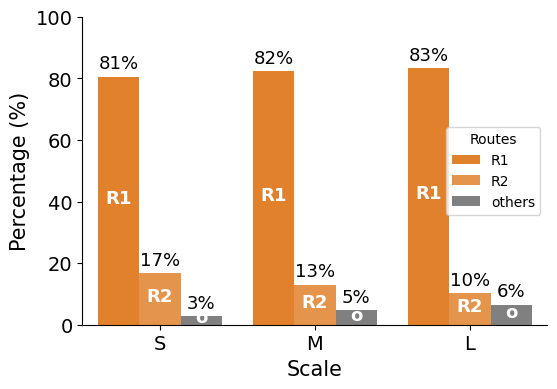

In [9]:
df = final_df.loc[final_df.cond == 'C3']
df = df.rename(columns={"count": "total"})

df.loc[:,['percentage']] = df.groupby('scale')['total'].apply(get_percentages).reset_index(level=0, drop=True)
df['sequence'].loc[df.percentage< 10 ] = 'others'
df
df['percentage'] = df.groupby(['scale','sequence'])['percentage'].transform('sum')
df = df.filter(['scale','','sequence','percentage']).drop_duplicates()
povoted = df.pivot(index = 'scale', columns='sequence',values = 'percentage')

povoted.columns =[ "R1", "R2","others"]## careful check number based on figure above 
povoted = povoted.loc[:, ['R1', 'R2','others']]   # 'Sr.no', 'Maths Score', 'Name'
cmap = ['#ff7f0e','#ff9232','grey']

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
#d = povoted.plot(kind='bar', stacked=False, color=cmap, ax=ax,width = 0.8 )
toplot = povoted.unstack().to_frame().reset_index().rename(columns={'level_0' : 'Routes', 0:'percentages'})
ax = sns.barplot(x="scale", y="percentages", data=toplot, palette=cmap,hue='Routes', dodge=True)

for c, route in zip(ax.containers, ['R1', 'R2','o']):
    ax.bar_label(c, fmt='%.0f%%', padding=3, fontsize=13, color='black')

    # Add route labels in the center of bars
    labels = [route] * len(c.datavalues)  # Repeat route label for each bar in the group
    ax.bar_label(c, labels=labels, label_type='center', padding=2, fontsize=13, color='white', weight='bold')
    #ax.bar_label(c, labels=toplot.Route, label_type='edge', padding=1)

    #ax.bar_label(c, label_type='center', padding=1)
# Group categories below 10% into 'Other'
# Get current legend
handles, labels = ax.get_legend_handles_labels()
print("Original Legend Labels:", labels)  # Debugging

# Define new legend labels
#

# Update legend
#ax.legend(handles, new_labels, title="Routes")

# Labels and formatting
plt.ylabel("Percentage (%)",fontsize= 15)
plt.xlabel("Scale",fontsize= 15)
#plt.title("Observed routes in Exp1-C2 per scale (%)",fontsize= 15)

plt.xticks(rotation=0)
plt.ylim(0, 100)
sns.despine(bottom = False, left = False)
ax.set_xticks([0,1, 2], ['S', 'M', 'L'],fontsize= 15)

ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)

plt.savefig(fig_folder+'Barplot_Exp1C2.png',dpi = 300,bbox_inches = 'tight')
plt.savefig(fig_folder+'Barplot_Exp1C2.svg',bbox_inches = 'tight')
plt.show()

## Fig 1B C3

Original Legend Labels: ['R1', 'R2', 'R3', 'others']


C:\Users\chado\AppData\Local\Temp\ipykernel_3940\914945121.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['sequence'].loc[df.percentage< 10 ] = 'others'
C:\Users\chado\AppData\Local\Temp\ipykernel_3940\914945121.py:5: SettingWithCopy

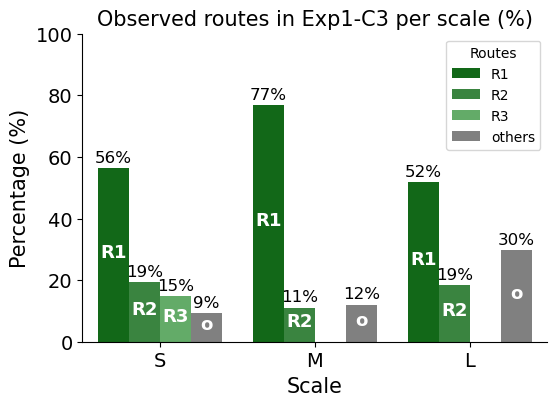

In [10]:
df = final_df.loc[final_df.cond == 'C4']
df = df.rename(columns={"count": "total"})

df.loc[:,['percentage']] = df.groupby('scale')['total'].apply(get_percentages).reset_index(level=0, drop=True)
df['sequence'].loc[df.percentage< 10 ] = 'others'
df
df['percentage'] = df.groupby(['scale','sequence'])['percentage'].transform('sum')
df = df.filter(['scale','','sequence','percentage']).drop_duplicates()
povoted = df.pivot(index = 'scale', columns='sequence',values = 'percentage')

povoted.columns =[ "R1", "R2","R3","others"]## careful check number based on figure above 
   # 'Sr.no', 'Maths Score', 'Name'
cmap = ['#04760b','#2e9035','#57b75d','grey']

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
#d = povoted.plot(kind='bar', stacked=False, color=cmap, ax=ax,width = 0.8 )
toplot = povoted.unstack().to_frame().reset_index().rename(columns={'level_0' : 'Routes', 0:'percentages'})
ax = sns.barplot(x="scale", y="percentages", data=toplot, palette=cmap,hue='Routes', dodge=True)

for c, route in zip(ax.containers, ['R1', 'R2','R3','o']):
    ax.bar_label(c, fmt='%.0f%%', padding=2, fontsize=12, color='black')

    # Add route labels in the center of bars
    labels = [route] * len(c.datavalues)  # Repeat route label for each bar in the group
    ax.bar_label(c, labels=labels, label_type='center', padding=2, fontsize=13, color='white', weight='bold')
    #ax.bar_label(c, labels=toplot.Route, label_type='edge', padding=1)

# Get current legend
handles, labels = ax.get_legend_handles_labels()
print("Original Legend Labels:", labels)  # Debugging

# Define new legend labels
#

# Update legend
#ax.legend(handles, new_labels, title="Routes")

# Labels and formatting
plt.ylabel("Percentage (%)",fontsize= 15)
plt.xlabel("Scale",fontsize= 15)
plt.title("Observed routes in Exp1-C3 per scale (%)",fontsize= 15)

plt.xticks(rotation=0)
plt.ylim(0, 100)
sns.despine(bottom = False, left = False)
ax.set_xticks([0,1, 2], ['S', 'M', 'L'],fontsize= 15)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)

#plt.savefig(fig_folder+'Barplot_Exp1C3.png',dpi = 300,bbox_inches = 'tight')
#plt.savefig(fig_folder+'Barplot_Exp1C3.svg',bbox_inches = 'tight')
plt.show()

# Fig 1C :

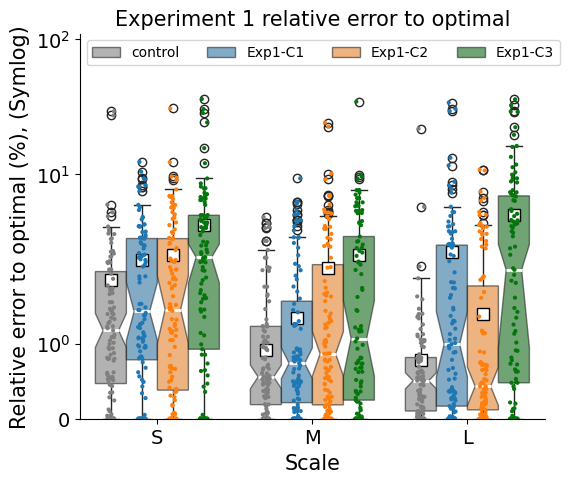

In [11]:
# folder to ave the figures : 
fig_folder = '../Figure_paper/'
toplot = DATA_nodemo.copy()
#toplot = toplot.loc[toplot.Configuration !=  'C1']
from scipy import stats
toplot['z_score'] = stats.zscore(toplot['perc_error'])
fig,axes=plt.subplots(1,1,figsize=(6, 5))
ax = axes
x      = 'Scale'
y      = 'perc_error'
#colors = ['#00a0a0', '#ff6f69']
hue = 'Configuration'
toplot_nooutliers=  toplot.loc[toplot.z_score <3 ]

logdf= toplot_nooutliers.copy()
logdf['Configuration'] = logdf['Configuration'].map({'C1': "control",'C2': "Exp1-C1", 'C3': "Exp1-C2", 'C4': "Exp1-C3", })
sns.boxplot(ax=ax,data=logdf, x=x, y=y, hue=hue,zorder=1,notch = True,showmeans=True,palette=['grey','#1f77b4','#ff7f0e','#04760b'],
            boxprops={'alpha': 0.6},meanprops={"marker":"s","markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"},medianprops={"color": "w", "linewidth": 2}) 
#np.log(logdf[y])#

#sns.lineplot(ax=ax, data=toplot_nooutliers, markers = True, x=x, y=y, hue=hue,err_style="bars",linewidth = 2 , errorbar=("se", 2))

sns.stripplot(ax=ax,data=logdf, x=x, y=y, hue=hue,alpha = 1, s= 3, palette=['grey','#1f77b4','#ff7f0e','#04760b'],dodge = True,legend=False)

sns.despine(bottom=False, left=False)
sns.despine(bottom=False, left=False)
ax.set_ylim(0, 110)
ax.set_ylabel('Relative error to optimal (%), (Symlog)',fontsize= 15)
ax.set_xlabel('Scale',fontsize= 15)
plt.xticks([0,1, 2], ['S', 'M','L'],fontsize= 15)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.legend(bbox_to_anchor=(1, 1),fontsize= 15)
ax.set(yscale="symlog")


ax.legend(ncols=4, bbox_to_anchor=(0, 0.9),
              loc='lower left', fontsize=10)
#ax.text(-0.1, 1.2, 'A', transform=ax.transAxes,
#    fontsize=20, fontweight='bold', va='top', ha='right')
ax.set_title('Experiment 1 relative error to optimal',fontsize= 15)
#plt.savefig(fig_folder+'Fig2bis_Preliminary_error_traj_.png',bbox_inches='tight',dpi= 330)
#plt.savefig(fig_folder+'Fig2bis_Preliminary_error_traj_.svg',bbox_inches='tight')

plt.show()

In [12]:
control_baseline = (
    toplot[toplot.Configuration == 'C1']
    .groupby('Scale')['perc_error']
    .median()
    .rename('baseline_error')
)
control_baseline


Scale
S1    1.192473
S2    0.557492
S3    0.505583
Name: baseline_error, dtype: float64

In [13]:
toplot = DATA_nodemo.copy()


# 2. On joint cette baseline à chaque ligne
toplot = toplot.join(control_baseline, on='Scale')

# 3. On crée la déviation corrigée :
#    - si Configuration == 'C1', on garde perc_error tel quel
#    - sinon on soustrait baseline_error
toplot['perc_error_corr'] = toplot.apply(
    lambda row: row['perc_error']
                if row['Configuration'] == 'C1'
                else row['perc_error'] - row['baseline_error'],
    axis=1
)

# Filtrage des outliers sur la nouvelle erreur corrigée
toplot['z_score'] = stats.zscore(toplot['perc_error_corr'])
toplot_nooutliers = toplot[toplot.z_score.abs() < 3]

# Données expérimentales (hors contrôle)
df_exp = toplot_nooutliers[toplot_nooutliers.Configuration != 'C1']
# Données contrôle
df_ctrl = toplot_nooutliers[toplot_nooutliers.Configuration == 'C1']

results = []

# Pour chaque échelle k
for k, group_exp in df_exp.groupby('Scale'):
    data_exp = group_exp['perc_error'].values
    data_ctrl = df_ctrl[df_ctrl.Scale == k]['perc_error'].values
    n_exp = len(data_exp)
    n_ctrl = len(data_ctrl)
    
    # mannwhitneyU test (wilcoxon signed rank)
    u_stat, p_val = stats.mannwhitneyu(data_exp, data_ctrl, alternative='two-sided')

    
    # Résultats
    results.append({
        'Scale': k,
        'n_exp': n_exp,
        'n_ctrl': n_ctrl,
        'mean_exp (%)': data_exp.mean(),
        'mean_ctrl (%)': data_ctrl.mean(),
        'u-stat': u_stat,
        'p-value (t-test)': p_val,
    })

df_results = pd.DataFrame(results)
df_results


,Scale,n_exp,n_ctrl,mean_exp (%),mean_ctrl (%),u-stat,p-value (t-test)
0,S1,320,107,3.001022,1.851389,21047.0,0.000372
1,S2,316,108,1.961749,0.915992,19798.0,0.012729
2,S3,303,108,2.965748,0.783488,20633.0,0.000055


## Fig 1 D

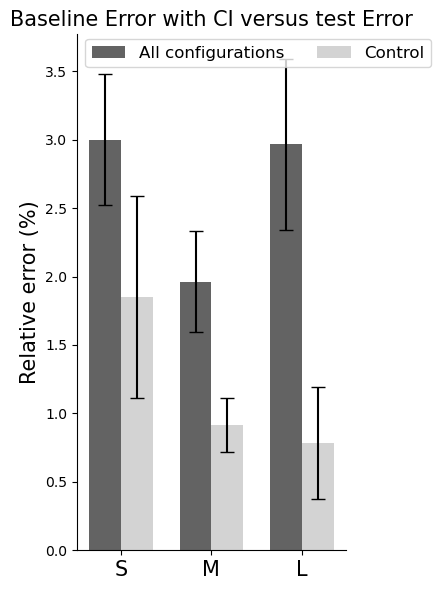

In [14]:
# Group and compute mean and CI95
summary = df_exp.groupby('Scale')['perc_error'].agg(['mean','sem']).reset_index()
summary_ctrl = df_ctrl.groupby('Scale')['perc_error'].agg(['mean','sem']).reset_index()
summary = summary.merge(summary_ctrl, on='Scale', suffixes=('_exp','_ctrl'))

# CI95
summary['ci95_exp'] = summary['sem_exp'] * stats.t.ppf(0.975, df=len(df_exp)-1)
summary['ci95_ctrl'] = summary['sem_ctrl'] * stats.t.ppf(0.975, df=len(df_ctrl)-1)

# Plotting
fig, ax = plt.subplots(figsize=(4,6))
x_positions = np.arange(len(summary))
width = 0.35

ax.bar(x_positions - width/2, summary['mean_exp'], width, yerr=summary['ci95_exp'],
       label='All configurations', capsize=5, color='#636363')
ax.bar(x_positions + width/2, summary['mean_ctrl'], width, yerr=summary['ci95_ctrl'],
       label='Control', capsize=5, color='lightgrey')


ax.set_xticks(x_positions)
ax.set_xticklabels(['S', 'M', 'L'],fontsize = 15)
ax.set_ylabel('Relative error (%)',fontsize = 15)
ax.set_title('Baseline Error with CI versus test Error',fontsize = 15)
ax.legend(ncols=2, bbox_to_anchor=(0, 0.92),
              loc='lower left', fontsize=12)
sns.despine()
plt.savefig(fig_folder+'Fig1C_Baseline_Error_.png',bbox_inches='tight',dpi= 330)
plt.savefig(fig_folder+'Fig1C_Baseline_Error_.svg',bbox_inches='tight')
plt.tight_layout()
plt.show()

In [15]:
toplot = toplot.filter(['Configuration', 'Scale', 'trial', 'session_num', 'user','perc_error',  'Session', 'accuracy', 'age', 'gender',
       'gaming_habits', 'route_planning', 'route_optimizations', 'GPS_usage'])

In [16]:
toplot.to_csv('../Combined_data/GLMM_Exp1.csv')